# Knowing How Things Relate

*The Mathematics of Machine Intelligence · Chapter 8*

Store a fact in one direction, then ask whether it can be read from the other end.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask how each fact is stored: with head, relation and tail marked, or as a bare association. If the facts live in a graph, flip the grid and check whether the reversed relation is the one intended (has mother is not child of). If the facts live in a trained model, test both directions on held-out wordings, and compare reported scores only when the scoring rule is the same. Say which of the three the system relies on: direction kept by design, recovered by training on reversed text, or built into the geometry.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 8, Knowing How Things Relate: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'
LIGHT = '#e8eef1'
WHITE_TEAL = LinearSegmentedColormap.from_list('mmi_white_teal', ['#ffffff', TEAL])
TEAL_WHITE_TERRA = LinearSegmentedColormap.from_list('mmi_gap', [TEAL, '#ffffff', TERRA])

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def pct(value, digits=3):
    return sig(100 * value, digits)

def panels(ratios=None):
    kwargs = {'gridspec_kw': {'width_ratios': ratios}} if ratios else {}
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y, size=11):
    ax.plot([x], [y], marker='o', markersize=size, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
TABLES = {'all pairs, first test': (0.569, 0.565), 'studied once': (0.329, 0.336), 'studied five times': (0.732, 0.718)}
REPORTED_Q = (0.88, 0.91)

def joint_table(p_forward, p_backward, phi):
    """Shares of pairs recalled both ways, forward only, backward only, neither, for a given correlation phi."""
    spread = math.sqrt(p_forward * (1 - p_forward) * p_backward * (1 - p_backward))
    both = p_forward * p_backward + phi * spread
    cells = {'both': both, 'forward only': p_forward - both, 'backward only': p_backward - both, 'neither': 1 - p_forward - p_backward + both}
    if min(cells.values()) < -1e-12:
        raise ValueError('That correlation is not possible with these averages.')
    return cells

def yule_q(cells):
    """Yule's Q for the two-by-two table of recalled both, forward only, backward only, neither; None when undefined."""
    ad = cells['both'] * cells['neither']
    bc = cells['forward only'] * cells['backward only']
    if ad + bc <= 1e-15:
        return None
    return (ad - bc) / (ad + bc)

def symmetry_picture(table='all pairs, first test', phi=0.0):
    p_f, p_b = TABLES[table]
    cells = joint_table(p_f, p_b, phi)
    q = yule_q(cells)
    independent = {'both': p_f * p_b, 'forward only': p_f * (1 - p_b), 'backward only': (1 - p_f) * p_b, 'neither': (1 - p_f) * (1 - p_b)}
    fig, ax = panels()
    names = list(cells)
    xs = np.arange(4)
    bars = ax[0].bar(xs, [100 * cells[n] for n in names], color=[TEAL, GOLD, DARK_GOLD, GREY], width=0.6)
    for x, n in zip(xs, names):
        ax[0].plot([x - 0.38, x + 0.38], [100 * independent[n]] * 2, color=NAVY, linestyle='dashed', linewidth=2)
    ax[0].plot([], [], color=NAVY, linestyle='dashed', linewidth=2, label='expected if the two ends were independent')
    for bar, n in zip(bars, names):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, 100 * cells[n] + 1.5, f'{100 * cells[n]:.1f}', va='bottom', fontsize=10)
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels(['recalled\nboth ways', 'forward\nonly', 'backward\nonly', 'neither'], fontsize=9)
    ax[0].set(ylabel='percent of pairs', title=f'Forward {100 * p_f:.1f}, backward {100 * p_b:.1f} percent', ylim=(0, 100))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.17))
    grid = np.linspace(0, 0.95, 96)
    ax[1].axhspan(REPORTED_Q[0], REPORTED_Q[1], color=GOLD, alpha=0.3)
    ax[1].plot(grid, [yule_q(joint_table(p_f, p_b, g)) for g in grid], color=NAVY, linewidth=3, label='Q for this table')
    tag(ax[1], 0.95, 0.2, 'gold band: reported Q\nfor retests, .88 to .91', fontsize=9, ha='right', color=DARK_GOLD)
    if q is not None:
        ring(ax[1], phi, q)
    ax[1].set(xlabel='how closely the two ends go together (correlation)', ylabel="Yule's Q (0 means no tie)", title='Same averages, different pair-by-pair tie', ylim=(-0.05, 1.05), xlim=(-0.02, 0.97))
    q_text = 'undefined (ad + bc is 0)' if q is None else sig(q)
    metrics = {'Recalled from both ends': f"{100 * cells['both']:.1f} percent", 'Expected if independent': f"{100 * independent['both']:.1f} percent", "Yule's Q": q_text, 'Forward and backward averages': f'{100 * p_f:.1f} and {100 * p_b:.1f} percent'}
    summary = f"Forward and backward recall average {100 * p_f:.1f} and {100 * p_b:.1f} percent in every state of this table, so the averages cannot tell the views apart. At correlation {sig(phi)}, {100 * cells['both']:.1f} percent of pairs come back from both ends, against {100 * independent['both']:.1f} if the ends were independent, giving Q = {q_text}."
    calc = f"Both ways = {p_f:g} x {p_b:g} + {sig(phi)} x sqrt({p_f:g} x {1 - p_f:.3g} x {p_b:g} x {1 - p_b:.3g}) = {cells['both']:.4f}. Forward only {cells['forward only']:.4f}, backward only {cells['backward only']:.4f}, neither {cells['neither']:.4f}. Q = (a d - b c) / (a d + b c) = {q_text}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
FAMILIES = {'Ana, Bea, Cy (the chapter)': (['Ana', 'Bea', 'Cy'], [(0, 1), (1, 2)]), 'Cy is also mother of Dee': (['Ana', 'Bea', 'Cy', 'Dee'], [(0, 1), (1, 2), (2, 3)]), 'Bea has two children, Cy and Dee': (['Ana', 'Bea', 'Cy', 'Dee'], [(0, 1), (1, 2), (1, 3)])}
GRIDS = ['mother of', 'has mother (flipped)', 'grandmother of (grid times itself)', 'two-way pair table']

def mother_grid(people, edges):
    grid = np.zeros((len(people), len(people)), dtype=int)
    for head, tail in edges:
        grid[head, tail] = 1
    return grid

def selected_grid(people, edges, which):
    a = mother_grid(people, edges)
    if which == 'mother of':
        return a
    if which == 'has mother (flipped)':
        return a.T.copy()
    if which == 'grandmother of (grid times itself)':
        return a @ a
    return np.minimum(a + a.T, 1)
QUESTIONS = {'mother of': 'Read a row: whom is she mother of?', 'has mother (flipped)': "Read a row: who is this person's mother?", 'grandmother of (grid times itself)': 'Read a row: whose maternal grandmother is she?', 'two-way pair table': 'Read a row: who is linked to this person?'}

def grid_picture(family='Ana, Bea, Cy (the chapter)', grid='mother of'):
    people, edges = FAMILIES[family]
    a = mother_grid(people, edges)
    g = selected_grid(people, edges, grid)
    n = len(people)
    fig, ax = panels([1, 1])
    ax[0].imshow(g, cmap=WHITE_TEAL, vmin=0, vmax=1.4)
    for i in range(n):
        for j in range(n):
            ax[0].text(j, i, str(g[i, j]), ha='center', va='center', fontsize=12, color='white' if g[i, j] else GREY, fontweight='bold' if g[i, j] else 'normal')
    ax[0].set_xticks(range(n))
    ax[0].set_xticklabels(people)
    ax[0].set_yticks(range(n))
    ax[0].set_yticklabels(people)
    ax[0].xaxis.tick_top()
    ax[0].set(title='', xlabel='')
    ax[0].grid(False)
    ax[0].set_ylabel('row: head', fontsize=10)
    for side in ('left', 'right', 'top', 'bottom'):
        ax[0].spines[side].set_visible(False)
    ax[0].tick_params(length=0)
    ax[0].set_title('column: tail\n' + grid, fontsize=10, pad=34)
    ax[0].xaxis.set_label_position('top')
    ax[1].axis('off')
    ax[1].grid(False)
    ax[1].text(0.0, 1.0, QUESTIONS[grid], fontsize=10, va='top', fontweight='bold', color=NAVY, wrap=True)
    for i, person in enumerate(people):
        answers = [people[j] for j in range(n) if g[i, j]]
        text = ', '.join(answers) if answers else 'no one'
        colour = GREY if not answers else TERRA if grid == 'two-way pair table' else TEAL
        ax[1].text(0.0, 0.84 - 0.14 * i, f'{person}:', fontsize=12, va='top', color=NAVY, fontweight='bold')
        ax[1].text(0.2, 0.84 - 0.14 * i, text, fontsize=12, va='top', color=colour)
    if grid == 'two-way pair table':
        note = 'The table returns partners but cannot say\nwhich one is the mother.'
    elif grid == 'has mother (flipped)':
        note = 'Same facts as the mother of grid, read from tail to head.\nNothing new is stored.'
    elif grid == 'grandmother of (grid times itself)':
        note = 'A new fact is derived by chaining two stored ones.'
    else:
        note = 'The stored facts, each with its roles marked.'
    ax[1].text(0.0, 0.84 - 0.14 * n - 0.03, note, fontsize=9.5, va='top', color=GREY)
    ax[1].set_xlim(0, 1)
    ax[1].set_ylim(0, 1)
    stored = int(a.sum())
    most = int(g.sum(axis=1).max())
    roles = {'mother of': 'yes', 'has mother (flipped)': 'yes, read tail to head', 'grandmother of (grid times itself)': 'yes', 'two-way pair table': 'no, either end could be the mother'}[grid]
    metrics = {'Ones in this grid': int(g.sum()), 'Stored mother of facts': stored, 'Most answers for one person': most, 'Roles kept': roles}
    facts = '; '.join((f'{people[h]} is mother of {people[t]}' for h, t in edges))
    if grid == 'has mother (flipped)':
        summary = f'Flipping the mother of grid gives has mother with the same {stored} facts and nothing new stored. Each person has at most one mother, so no row of the flipped grid has more than one 1, while a mother may have several children.'
        calc = f'Stored: {facts}. A_(r inverse) = A_r transposed, so entry (tail, head) of the flip equals entry (head, tail) of the original. Row sums of the flip: ' + ', '.join((f'{people[i]} {int(g[i].sum())}' for i in range(n))) + '.'
    elif grid == 'grandmother of (grid times itself)':
        pairs = [f'{people[i]} to {people[k]}' for i in range(n) for k in range(n) if g[i, k]]
        summary = f'Multiplying the grid by itself counts two-step chains of mother of. It holds {int(g.sum())} derived grandmother fact' + ('s' if g.sum() != 1 else '') + ', none of them stored directly.'
        calc = f'Stored: {facts}. (A x A) at (i, k) = sum over j of A(i, j) A(j, k). Derived: ' + (', '.join(pairs) if pairs else 'none') + '.'
    elif grid == 'two-way pair table':
        summary = f"A table that links each pair both ways answers any row, but it returns mothers and children together. Row {people[1]} lists {', '.join((people[j] for j in range(n) if g[1, j]))}, and the table cannot say which of them is the mother."
        calc = f'Stored: {facts}. Table = A + A transposed, entries above 1 set to 1, so it holds {int(g.sum())} ones from {stored} facts and the roles are gone.'
    else:
        summary = f'The grid has a 1 where the row person is mother of the column person, {stored} ones in all. Each fact is stored with its head, relation and tail, so the roles are marked.'
        calc = f'Stored: {facts}. A(head, tail) = 1 for each; every other entry is 0.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
BERGLUND = {'description-first': (96.7, 0.1), 'name-first': (50.0, 0.0)}
ASKS = {'description-first': ('description given,\nname asked', 'name given,\ndescription asked'), 'name-first': ('name given,\ndescription asked', 'description given,\nname asked')}

def reversal_curse_picture(kind='description-first', order='trained order'):
    trained, reverse = BERGLUND[kind]
    chosen = trained if order == 'trained order' else reverse
    other = reverse if order == 'trained order' else trained
    fig, ax = panels()
    bars = ax[0].bar([0, 1], [trained, reverse], color=[TEAL, TERRA], width=0.55)
    for bar, v in zip(bars, [trained, reverse]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 9, f'{v:.1f}', va='bottom')
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels([f'trained order\n{ASKS[kind][0]}', f'reverse order\n{ASKS[kind][1]}'], fontsize=9)
    ax[0].set(ylabel='exact-match score (percent)', title=f'{kind} facts', ylim=(0, 112))
    ring(ax[0], 0 if order == 'trained order' else 1, chosen, 14)
    values = [BERGLUND['description-first'][0], BERGLUND['description-first'][1], BERGLUND['name-first'][0], BERGLUND['name-first'][1]]
    xs = [0, 1, 2.6, 3.6]
    ax[1].bar(xs, values, color=[TEAL, TERRA, TEAL, TERRA], width=0.8)
    for x, v in zip(xs, values):
        tag(ax[1], x, v + 9, f'{v:.1f}', va='bottom', fontsize=10)
    idx = (0 if kind == 'description-first' else 2) + (0 if order == 'trained order' else 1)
    ring(ax[1], xs[idx], values[idx], 14)
    ax[1].set_xticks([0.5, 3.1])
    ax[1].set_xticklabels(['description-first', 'name-first'])
    ax[1].set(ylabel='exact-match score (percent)', title='All four reported scores', ylim=(0, 112))
    ax[1].plot([], [], marker='s', linestyle='none', color=TEAL, label='trained order')
    ax[1].plot([], [], marker='s', linestyle='none', color=TERRA, label='reverse order')
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
    metrics = {'Selected score': f'{chosen:.1f} percent', 'Same facts, other order': f'{other:.1f} percent', 'Drop from trained to reverse': f'{trained - reverse:.1f} points', 'Model': 'GPT-3, 175 billion parameters'}
    summary = f"On {kind} facts the fine-tuned model scored {trained:.1f} percent asked in the trained order and {reverse:.1f} percent asked from the other end. These are exact-match scores on the paper's invented facts, so the {trained - reverse:.1f}-point drop describes that test, not people or all models."
    calc = f'Reported (Table 1 of the paper, as quoted in the chapter): trained order {trained:.1f}, reverse {reverse:.1f}. Drop = {trained:.1f} - {reverse:.1f} = {trained - reverse:.1f} points. Exact match counts an answer only if it equals the target.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
GOLOVNEVA = {'name-first': {'standard fine-tuning': 0.0, 'names kept in order': 89.7, 'random chunks': 99.0}, 'description-first': {'standard fine-tuning': 4.0, 'names kept in order': 6.0, 'random chunks': 70.0}}
METHODS = ['standard fine-tuning', 'names kept in order', 'random chunks']
SENTENCES = {'name-first': 'Uriah Hawthorne is the composer of Abyssal Melodies', 'description-first': 'The composer of Abyssal Melodies is Uriah Hawthorne'}
NAME = 'Uriah Hawthorne'
FORWARD_RANGE = (78.3, 80.3)

def reversed_copy(sentence, method, seed=7):
    """Illustrative reversed copy of a sentence. Words stand in for tokens; the paper's exact preprocessing is not in the chapter."""
    if method == 'standard fine-tuning':
        return None
    if method == 'names kept in order':
        units = []
        words = sentence.split()
        i = 0
        while i < len(words):
            if ' '.join(words[i:i + 2]) == NAME:
                units.append(NAME)
                i += 2
            else:
                units.append(words[i])
                i += 1
        return ' '.join(units[::-1])
    rng = np.random.default_rng(seed)
    words = sentence.split()
    chunks, i = ([], 0)
    while i < len(words):
        size = int(rng.integers(1, 4))
        chunks.append(words[i:i + size])
        i += size
    return ' | '.join((' '.join(c) for c in chunks[::-1]))

def reverse_training_picture(kind='name-first', method='standard fine-tuning'):
    scores = GOLOVNEVA[kind]
    score = scores[method]
    base = scores['standard fine-tuning']
    fig, ax = panels([1.1, 1])
    ax[0].axis('off')
    ax[0].grid(False)
    ax[0].set_xlim(0, 1)
    ax[0].set_ylim(0, 1)
    sentence = SENTENCES[kind]
    copy = reversed_copy(sentence, method)
    import textwrap
    ax[0].text(0.0, 0.97, 'Training text (an illustration)', fontsize=10, fontweight='bold', color=NAVY, va='top')
    ax[0].text(0.0, 0.88, 'original:', fontsize=9.5, color=GREY, va='top')
    ax[0].text(0.0, 0.83, textwrap.fill(sentence, 36), fontsize=10.5, color=NAVY, va='top')
    ax[0].text(0.0, 0.64, 'reversed copy added:', fontsize=9.5, color=GREY, va='top')
    if copy is None:
        ax[0].text(0.0, 0.59, 'none (the original only)', fontsize=10.5, color=GREY, va='top')
    else:
        ax[0].text(0.0, 0.59, textwrap.fill(copy, 36), fontsize=10.5, color=TEAL, va='top')
    ax[0].text(0.0, 0.27, 'Words stand in for tokens. In random chunks, bars\nmark the cuts and each chunk keeps its word order.', fontsize=8.5, color=GREY, va='top')
    ax[0].text(0.0, 0.03, f'Reversed-question score: {score:.1f} percent', fontsize=11, fontweight='bold', color=NAVY, va='bottom')
    xs, values, colours = ([], [], [])
    for gi, k in enumerate(['name-first', 'description-first']):
        for mi, m in enumerate(METHODS):
            xs.append(gi * 4 + mi)
            values.append(GOLOVNEVA[k][m])
            colours.append([GREY, GOLD, TEAL][mi])
    ax[1].bar(xs, values, color=colours, width=0.8)
    for x, v in zip(xs, values):
        tag(ax[1], x, v + 7, f'{v:.1f}', va='bottom', fontsize=9)
    index = (0 if kind == 'name-first' else 3) + METHODS.index(method)
    ring(ax[1], xs[index], values[index], 14)
    ax[1].set_xticks([1, 5])
    ax[1].set_xticklabels(['name-first', 'description-first'])
    for color, label in [(GREY, 'standard'), (GOLD, 'names kept'), (TEAL, 'random chunks')]:
        ax[1].plot([], [], marker='s', linestyle='none', color=color, label=label)
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
    ax[1].set(ylabel='reversed-question score (percent)', title='Soft-match scores, 7B model', ylim=(0, 115))
    forward = f'{FORWARD_RANGE[0]:g} to {FORWARD_RANGE[1]:g} percent' if kind == 'name-first' else 'not quoted in the chapter'
    metrics = {'Reversed-question score': f'{score:.1f} percent', 'Standard fine-tuning, same facts': f'{base:.1f} percent', 'Gain over standard': f'{score - base:.1f} points', 'Forward accuracy': forward}
    summary = f'On {kind} facts, reversed questions scored {score:.1f} percent with {method}, against {base:.1f} with standard fine-tuning. These are soft-match scores from one preprint on invented facts, not like for like with the exact-match scores of the previous demonstration.'
    calc = f"Reported scores (the chapter's Figure 8.5): {kind} facts, {method}: {score:.1f}. Gain = {score:.1f} - {base:.1f} = {score - base:.1f} points. The number of facts and runs behind the table is not stated."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

@lru_cache(maxsize=None)
def toy_run(reversed_copies, entities, steps=100, facts=5, dim=8, seed=2026, rate=0.1):
    """Softmax lookup with separate input and output vectors, trained on facts a -> b by gradient descent.
    Returns the mean chance of the right answer for the forward question and the reversed question after each step."""
    rng = np.random.default_rng(seed)
    first = np.arange(facts)
    second = entities // 2 + np.arange(facts)
    xs = np.concatenate([first, second]) if reversed_copies else first
    ys = np.concatenate([second, first]) if reversed_copies else second
    inputs = rng.normal(0, 0.3, (entities, dim))
    outputs = rng.normal(0, 0.3, (entities, dim))

    def answer_chance(queries, targets):
        logits = inputs[queries] @ outputs.T
        logits = logits - logits.max(axis=1, keepdims=True)
        p = np.exp(logits)
        p /= p.sum(axis=1, keepdims=True)
        return (p, p[np.arange(len(queries)), targets].mean())
    forward, backward = ([], [])
    for _ in range(steps + 1):
        forward.append(answer_chance(first, second)[1])
        backward.append(answer_chance(second, first)[1])
        p, _ = answer_chance(xs, ys)
        g = p.copy()
        g[np.arange(len(xs)), ys] -= 1
        d_in = np.zeros_like(inputs)
        np.add.at(d_in, xs, g @ outputs)
        d_out = g.T @ inputs[xs]
        inputs -= rate * d_in
        outputs -= rate * d_out
    return (np.array(forward), np.array(backward))
TRAININGS = ['forward facts only', 'forward plus reversed copies']

def toy_reversal_picture(training='forward facts only', entities=20, steps=50):
    fwd, back = toy_run(training != 'forward facts only', entities)
    chance = 1 / entities
    fig, ax = panels()
    t = np.arange(len(fwd))
    ax[0].plot(t, 100 * fwd, color=TEAL, linewidth=2.5, label='forward question')
    ax[0].plot(t, 100 * back, color=TERRA, linewidth=2.5, linestyle='dashed', label='reversed question')
    ax[0].axhline(100 * chance, color=GREY, linestyle='dotted', linewidth=1.2, label=f'chance, 1 in {entities}')
    ax[0].axvline(steps, color=NAVY, linewidth=1, linestyle='dotted')
    ring(ax[0], steps, 100 * fwd[steps])
    ring(ax[0], steps, 100 * back[steps])
    ax[0].set(xlabel='training steps', ylabel='chance of the right answer (percent)', title='Toy lookup, ' + training, ylim=(-3, 108), xlim=(-2, 102))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    width = 0.35
    for gi, name in enumerate(TRAININGS):
        f2, b2 = toy_run(name != 'forward facts only', entities)
        ax[1].bar(gi - width / 2, 100 * f2[steps], width=width, color=TEAL, label='forward question' if gi == 0 else None)
        ax[1].bar(gi + width / 2, 100 * b2[steps], width=width, color=TERRA, label='reversed question' if gi == 0 else None)
        tag(ax[1], gi - width / 2, 100 * f2[steps] + 2, f'{100 * f2[steps]:.1f}', va='bottom', fontsize=9)
        tag(ax[1], gi + width / 2, 100 * b2[steps] + 2, f'{100 * b2[steps]:.1f}', va='bottom', fontsize=9)
    ax[1].axhline(100 * chance, color=GREY, linestyle='dotted', linewidth=1.2)
    chosen = TRAININGS.index(training)
    ax[1].annotate('selected', (chosen, 113), ha='center', fontsize=9.5, color=NAVY, fontweight='bold')
    ax[1].set_xticks([0, 1])
    ax[1].set_xticklabels(['forward facts only', 'forward plus\nreversed copies'], fontsize=9)
    ax[1].set(ylabel='chance of the right answer (percent)', title=f'After {steps} steps', ylim=(0, 124))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2)
    metrics = {'Forward question': f'{100 * fwd[steps]:.1f} percent', 'Reversed question': f'{100 * back[steps]:.1f} percent', 'Chance level': f'{100 * chance:.1f} percent', 'Facts trained': '5, each as a to b'}
    summary = f'After {steps} steps of {training} among {entities} entities, the toy answers the forward question {100 * fwd[steps]:.1f} percent of the time and the reversed one {100 * back[steps]:.1f} percent, against {100 * chance:.1f} by chance. This is a constructed toy with a seeded start, not a language model and not a theorem.'
    calc = f'Each entity has an input vector and an output vector (8 numbers each, seed 2026). A question about x gets chance exp(u_x . v_y) / sum over j of exp(u_x . v_j) for answer y. Training moves only the vectors involved, 5 facts, step size 0.1, {steps} steps.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TOWNS = {'Ash': 0, 'Birch': 1, 'Cedar': 2}
STEPS = {'one stride east': 1, 'one stride west': -1, 'no step (zero)': 0}

def gap_score(head, step, tail):
    """The chapter's score f = length of (head + step - tail), here on a line."""
    return abs(head + step - tail)

def strides(n):
    return f'{sig(n)} stride' + ('' if abs(n - 1) < 1e-12 else 's')

def translation_picture(head='Ash', tail='Birch', step='one stride east'):
    h, t, r = (TOWNS[head], TOWNS[tail], STEPS[step])
    landing = h + r
    score = gap_score(h, r, t)
    swapped = gap_score(t, r, h)
    fig, ax = panels([1.15, 1])
    ax[0].axhline(0, color=GREY, linewidth=1.5)
    for name, x in TOWNS.items():
        ax[0].plot([x], [0], marker='o', markersize=9, color=NAVY)
        ax[0].text(x, -0.13, name, ha='center', va='top', fontsize=10.5, color=NAVY)
    ring(ax[0], h, 0, 17)
    ax[0].plot([t], [0], marker='s', markersize=14, markerfacecolor='none', markeredgecolor=TERRA, markeredgewidth=2.2, zorder=5)
    if h == t:
        ax[0].text(h, -0.36, 'head and tail', ha='center', va='top', fontsize=9, color=NAVY)
    else:
        ax[0].text(h, -0.36, 'head', ha='center', va='top', fontsize=9, color=TEAL)
        ax[0].text(t, -0.36, 'tail', ha='center', va='top', fontsize=9, color=TERRA)
    if r != 0:
        ax[0].annotate('', xy=(landing, 0.25), xytext=(h, 0.25), arrowprops={'arrowstyle': '->', 'color': TEAL, 'linewidth': 2.5})
    ax[0].plot([landing], [0.25], marker='x', markersize=10, color=TEAL, markeredgewidth=2.5, zorder=7)
    ax[0].text(landing, 0.32, 'lands here', ha='center', va='bottom', fontsize=8.5, color=TEAL)
    if score > 0:
        ax[0].annotate('', xy=(t, -0.78), xytext=(landing, -0.78), arrowprops={'arrowstyle': '<->', 'color': DARK_GOLD, 'linewidth': 1.8})
        tag(ax[0], (landing + t) / 2, -0.9, f'gap {score:g} strides', va='top', fontsize=10, color=DARK_GOLD)
    else:
        tag(ax[0], t, -0.9, 'gap 0: the fact fits', va='top', fontsize=10, color=TEAL)
    ax[0].set(xlim=(-1.6, 3.6), ylim=(-1.25, 0.7), xlabel='position along the road (strides)', title=f'{head} head, {tail} tail, {step}')
    ax[0].set_yticks([])
    ax[0].set_xticks([-1, 0, 1, 2, 3])
    ax[0].grid(False)
    heads = ['Ash', 'Birch', 'Cedar']
    tails = ['Ash', 'Birch', 'Cedar']
    mat = np.array([[gap_score(TOWNS[a], r, TOWNS[b]) for b in tails] for a in heads])
    ax[1].imshow(mat, cmap=TEAL_WHITE_TERRA, vmin=0, vmax=4)
    for i in range(3):
        for j in range(3):
            ax[1].text(j, i, f'{mat[i, j]:g}', ha='center', va='center', fontsize=13, color='white' if mat[i, j] in (0, 4) else NAVY, fontweight='bold')
    ring(ax[1], tails.index(tail), heads.index(head), 30)
    ax[1].set_xticks(range(3))
    ax[1].set_xticklabels(tails)
    ax[1].set_yticks(range(3))
    ax[1].set_yticklabels(heads)
    ax[1].xaxis.tick_top()
    ax[1].xaxis.set_label_position('top')
    ax[1].set_xlabel('tail', fontsize=10)
    ax[1].set_ylabel('head', fontsize=10)
    ax[1].set_title('Gap f for every pair, ' + step, fontsize=10, pad=30)
    ax[1].grid(False)
    names = {v: k for k, v in TOWNS.items()}
    metrics = {'Gap f (strides)': sig(score), 'Step lands at': names.get(landing, f'{landing:g}, no town'), 'Fits exactly': 'yes' if score == 0 else 'no', 'Swap head and tail, same step': strides(swapped)}
    move = 'no step' if r == 0 else f'a step of {r:+d}'
    summary = f'From {head} at {h}, {move} lands at {landing:g}, and the tail {tail} is at {t}, so the gap is {strides(score)}. Swapping the roles with the same step gives a gap of {strides(swapped)}; negating the step on the swapped pair always gives back {sig(score)}.'
    calc = f'f = |h + r - t| = |{h} + ({r}) - {t}| = {sig(score)}. Swapped, same step: |{t} + ({r}) - {h}| = {sig(swapped)}. Swapped with the negated step: |{t} + ({-r}) - {h}| = {sig(gap_score(t, -r, h))}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TOWN_COUNT = 30
REPETITIONS = 200

def true_tail_ranks(positions):
    """Rank of the true tail (the next town east) when every other town is a candidate. positions: (reps, towns)."""
    reps, n = positions.shape
    heads = np.arange(n - 1)
    gaps = np.abs(positions[:, heads, None] + 1.0 - positions[:, None, :])
    gaps[:, heads, heads] = np.inf
    true_gap = gaps[:, heads, heads + 1]
    return 1 + (gaps < true_gap[:, :, None]).sum(axis=2)

@lru_cache(maxsize=None)
def rank_sample(noise, seed=2026):
    rng = np.random.default_rng(seed)
    positions = np.arange(TOWN_COUNT) + noise * rng.normal(size=(REPETITIONS, TOWN_COUNT))
    return true_tail_ranks(positions).ravel()

def hits(noise, k):
    return float((rank_sample(noise) <= k).mean())
NOISES = [0, 0.25, 0.5, 1, 2, 4]
CUTOFFS = [1, 3, 10]

def hits_picture(noise=0.5, k=3):
    ranks = rank_sample(noise)
    candidates = TOWN_COUNT - 1
    h = hits(noise, k)
    fig, ax = panels()
    counts = np.array([(ranks == r).sum() for r in range(1, candidates + 1)]) / len(ranks)
    colours = [TEAL if r <= k else LIGHT for r in range(1, candidates + 1)]
    ax[0].bar(range(1, candidates + 1), 100 * counts, color=colours, edgecolor=GREY, linewidth=0.4)
    ax[0].axvline(k + 0.5, color=NAVY, linestyle='dashed', linewidth=1.5)
    tag(ax[0], min(candidates - 3, k + 1.5 + 6), max(100 * counts) * 0.9, f'hits at {k}: {100 * h:.1f} percent', fontsize=10.5, color=TEAL)
    ax[0].set(xlabel='rank of the true next town (1 is best)', ylabel='percent of tests', title=f'Position error sd {noise:g} stride' + ('' if noise == 1 else 's'), xlim=(0, candidates + 1))
    xs = np.arange(len(NOISES))
    for kk, style, colour in [(1, 'dotted', GREY), (3, 'dashed', GOLD), (10, 'solid', TEAL)]:
        chosen = kk == k
        ax[1].plot(xs, [100 * hits(n, kk) for n in NOISES], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'hits at {kk}')
    ax[1].axhline(100 * k / candidates, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 0.05, 100 * k / candidates - 2.5, f'chance for k = {k}', ha='left', va='top', fontsize=9, color=GREY)
    ring(ax[1], NOISES.index(noise), 100 * h)
    ax[1].set_xticks(xs)
    ax[1].set_xticklabels([f'{n:g}' for n in NOISES])
    ax[1].set(xlabel='error sd in each learned position (strides)', ylabel='hits (percent)', title='Hits fall as positions blur', ylim=(-3, 105))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    metrics = {f'Hits at {k}': f'{100 * h:.1f} percent', 'Chance level': f'{100 * k / candidates:.1f} percent', 'Median rank of the true town': sig(float(np.median(ranks))), 'Tests': f'{len(ranks)} ({REPETITIONS} blurs x {TOWN_COUNT - 1} towns)'}
    summary = f'With each learned position blurred by sd {noise:g} stride' + ('' if noise == 1 else 's') + f", the true next town ranks in the top {k} in {100 * h:.1f} percent of tests, against {100 * k / candidates:.1f} by chance among {candidates} candidates. This is a constructed road of {TOWN_COUNT} towns, not a benchmark, and its numbers do not compare with the paper's."
    calc = f'Rank of the true tail = 1 + the number of other towns whose gap |h + 1 - t| is smaller than the true gap. Hits at {k} = tests with rank <= {k} divided by {len(ranks)}. Positions are the integers 0 to {TOWN_COUNT - 1} plus normal error with sd {noise:g}, seed 2026.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C08-D01: Do equal averages show that a word pair is stored both ways?

If students recall about 57 percent of pairs from either end, what would the pair-by-pair record have to look like to count against two independent links?

A pair can be recalled from both ends, one end or neither. If recall from each end were independent, the share recalled both ways would be the product of the two averages, 0.569 x 0.565. When the ends go together, that share rises while the two averages stay put. Yule's Q turns the two-by-two table into one number from 0 (no tie) toward 1.

$$
Q=\frac{ad-bc}{ad+bc},\qquad a=p_fp_b+\phi\sqrt{p_f(1-p_f)\,p_b(1-p_b)}
$$

**Symbols:** p_f, p_b: share of pairs recalled forward and backward on the first test; phi: how closely recall from the two ends goes together, pair by pair; 0 means independent; a, b, c, d: shares of pairs recalled both ways, forward only, backward only, and neither; Q: Yule's Q, a tie between two yes/no outcomes: 0 for none, near 1 when they go together

**Predict before looking:** The averages are 56.9 and 56.5 percent. If the two ends were independent, what share of pairs would students recall from both ends? Then move the correlation up and watch that share.

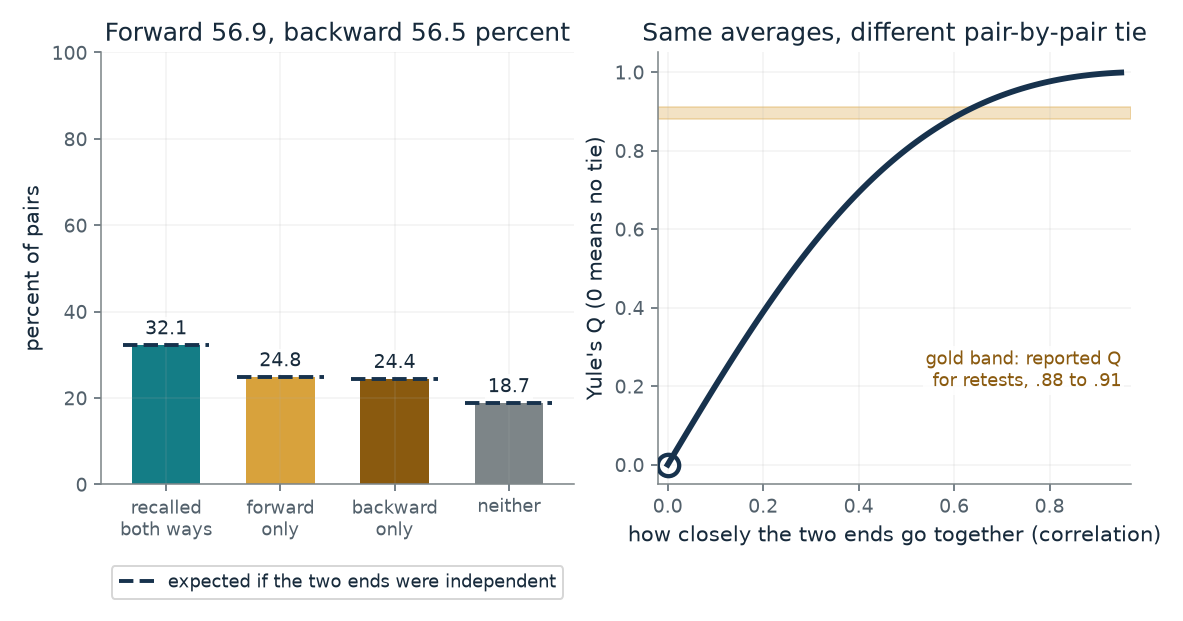

- **Recalled from both ends:** 32.1 percent
- **Expected if independent:** 32.1 percent
- **Yule's Q:** 0
- **Forward and backward averages:** 56.9 and 56.5 percent

Forward and backward recall average 56.9 and 56.5 percent in every state of this table, so the averages cannot tell the views apart. At correlation 0, 32.1 percent of pairs come back from both ends, against 32.1 if the ends were independent, giving Q = 0.

Both ways = 0.569 x 0.565 + 0 x sqrt(0.569 x 0.431 x 0.565 x 0.435) = 0.3215. Forward only 0.2475, backward only 0.2435, neither 0.1875. Q = (a d - b c) / (a d + b c) = 0.

In [2]:
figure, values, explanation = symmetry_picture(**{'table': 'all pairs, first test', 'phi': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Do equal averages show that a word pair is stored both ways?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which pairs = all pairs, first test, Correlation between the two ends (pair by pair) = 0.6: At correlation 0.6, 46.9 percent of pairs come back from both ends, against 32.1 percent under independence, and Q is 0.884, about the size of the reported .88. The two averages never moved.

**Takeaway:** Equal forward and backward averages are the same under independence and under strong ties; only the pair-by-pair record separates them.

**Why it matters:** A system can look symmetric on average and still store two unrelated links. The test that decides is whether recall from one end predicts recall from the other for the same pair.

**In brains and behavior:** Fifteen students studied random noun pairs. Pair by pair, recall from one end tended to go with recall from the other, which weighs against independent links under the paper's assumptions. The pairs were not facts, and the neural mechanism is not shown.

**In machines:** A pair table with equal strengths in both directions returns the partner from either cue. That is a specification of a table, not a measured mechanism in the students.

**Where it applies:** The curve is a construction: it fixes the two averages and varies the tie between them. The reported .88 and .91 come from retests of the same pairs, so they are reference marks, not points on this curve. Equal averages fit both a symmetric link and two independent links, as the paper says; they do not show a mechanism in the students' brains.

**Check your understanding:** In the studied-once table the averages are 32.9 and 33.6 percent. With correlation 0, what share of pairs is recalled from both ends?

<details><summary>Show the answer</summary>

0.329 x 0.336 = 0.1105, so 11.1 percent. At correlation 0.8 the share is 28.8 percent, although the two averages are unchanged.

</details>

*Source: Chapter 8, Fifteen students recalled new random noun pairs about equally well from either end. Reported averages from the chapter's source note on Kahana (2002): first-test forward .569 and backward .565, and the once and five-times values .329, .336 and .732, .718. The chapter and its note give Yule's Q near unity (.88 and .91) for retests; the pair table at each correlation and the Q curve are this companion's own construction on those averages.*

## C08-D02: How does flipping a grid read a fact from the other end?

If a grid stores who is mother of whom, what does the flipped grid answer, and what does a two-way pair table lose?

The grid has a 1 where a stored fact holds. Flipping it across its diagonal swaps heads and tails, so the same ones now answer the reverse question. Multiplying the grid by itself chains two facts into a grandmother fact. A table that fills in both directions loses the roles, so Bea's row lists her mother and her children together.

$$
A_{r^{-1}}=A_r^{\top}
$$

$$
(A_r^{2})_{ik}=\sum_j (A_r)_{ij}(A_r)_{jk}
$$

**Symbols:** A_r: grid with a 1 where the row person is mother of the column person, and 0 elsewhere; A_(r inverse): the relation read from the other end: has mother; top: the flip across the diagonal: rows become columns; A_r^2: the grid times itself: a 1 where two mother of facts chain, a maternal grandmother

**Predict before looking:** After the flip, how many ones are in the grid, and which person's row of the flipped grid can never hold more than one 1?

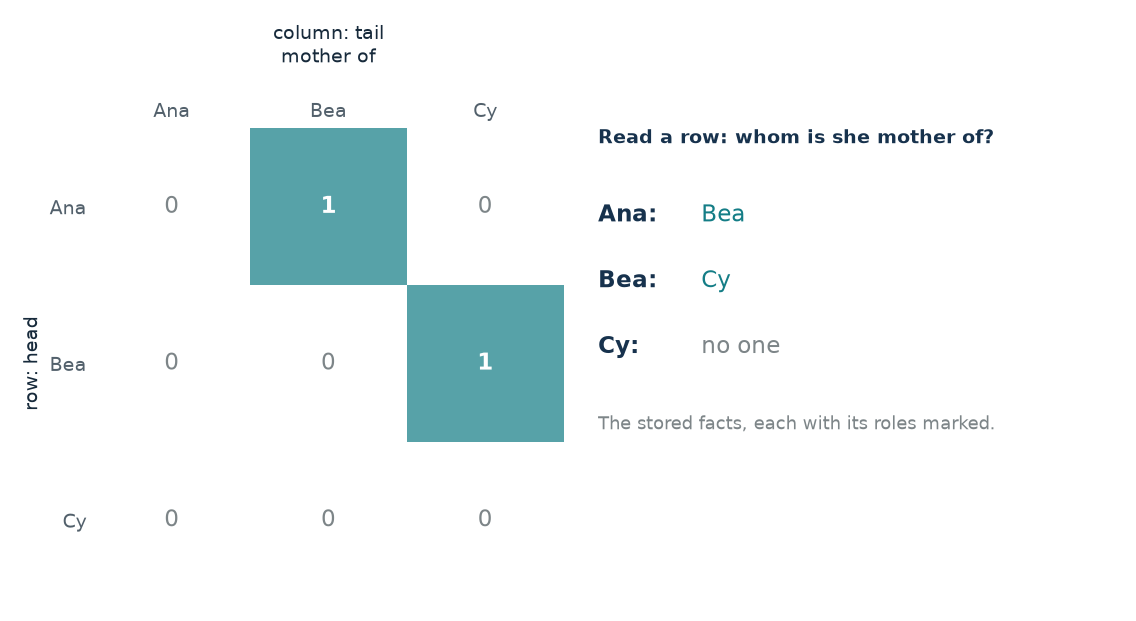

- **Ones in this grid:** 2
- **Stored mother of facts:** 2
- **Most answers for one person:** 1
- **Roles kept:** yes

The grid has a 1 where the row person is mother of the column person, 2 ones in all. Each fact is stored with its head, relation and tail, so the roles are marked.

Stored: Ana is mother of Bea; Bea is mother of Cy. A(head, tail) = 1 for each; every other entry is 0.

In [3]:
figure, values, explanation = grid_picture(**{'family': 'Ana, Bea, Cy (the chapter)', 'grid': 'mother of'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does flipping a grid read a fact from the other end?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Family = Cy is also mother of Dee, Which grid = has mother (flipped): With Cy mother of Dee added, the flipped grid has Dee's row pointing to Cy. It holds the same 3 ones as the original and stores no new fact.

**Takeaway:** The flip reads each fact from tail to head with nothing new stored; the two-way table answers any row but cannot say who is the mother.

**Why it matters:** The graph keeps direction because a designer built the roles in. A symmetric association retrieves a partner but erases which end played which part.

**In brains and behavior:** Whether people reverse facts through something like a flipped grid is not established. The chapter says the neural mechanism for retaining paired facts and their roles remains unresolved.

**In machines:** A knowledge graph is a specification: facts stored as head, relation and tail triples, and a flip reads them backward by design.

**Where it applies:** Every fact is stored with its head, relation and tail marked. The flip gives has mother, not child of, which would also cover a father's children. In this family each child has one mother, but a mother may have many children; someone has to say which holds.

**Check your understanding:** In the Bea-has-two-children family, how many ones does the flipped grid have, and how many does a two-way pair table hold?

<details><summary>Show the answer</summary>

The flipped grid has 3 ones, the same as the 3 stored facts. The two-way table has 6 ones, since each fact appears in both directions, and Bea's row lists Ana, Cy and Dee with no way to tell the mother from the children.

</details>

*Source: Chapter 8, A knowledge graph and the flipped grid. Book equation and the chapter's made-up family (Ana, Bea, Cy). The extra rows for Dee follow the chapter's practice question and one constructed variant; nothing here is data.*

## C08-D03: What did the reversal-curse experiment actually score?

A fine-tuned model scored 96.7 percent in one direction and 0.1 in the other. What was scored, on which facts, and what does that leave open?

For a description-first fact the trained order gives the description and asks for the name; the reverse gives the name and asks for the description. Exact match marks an answer right only if it equals the target, which is easier for names than for descriptions. That is why name-first facts score lower even in the trained order.

$$
\text{exact match}=\frac{\text{answers equal to the target}}{\text{questions asked}}
$$

**Symbols:** exact match: an answer counts as right only if it equals the target; trained order: the question is asked in the order the fact was shown in training; reverse order: the same fact asked from the other end

**Predict before looking:** Name-first facts scored 50.0 percent in the trained order. Predict the reverse score before you choose that fact kind.

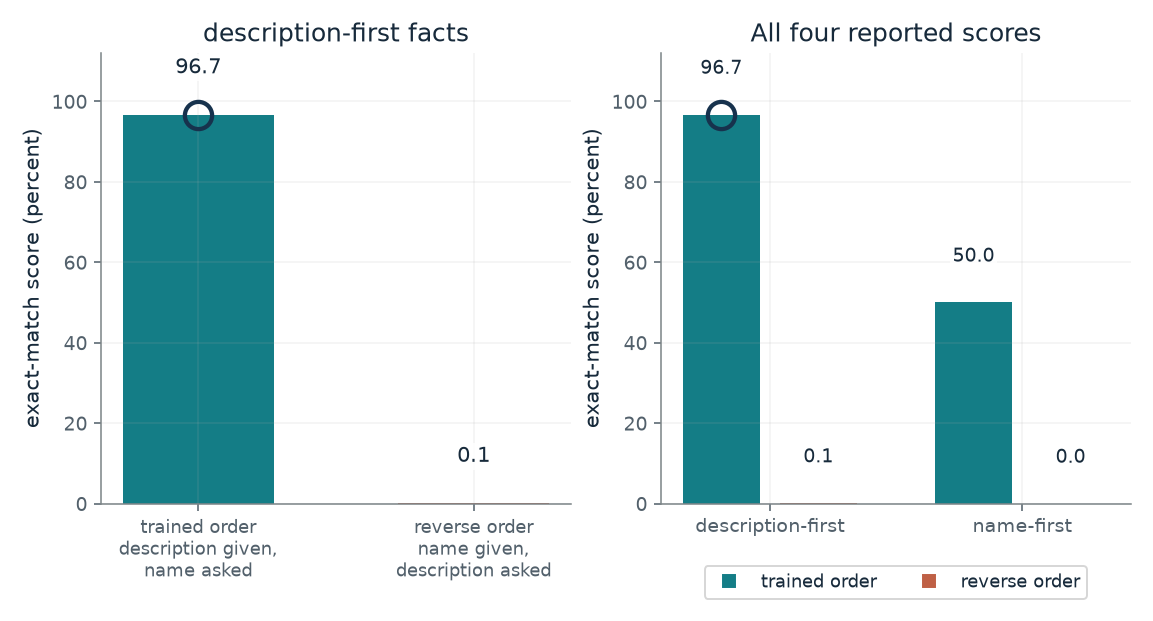

- **Selected score:** 96.7 percent
- **Same facts, other order:** 0.1 percent
- **Drop from trained to reverse:** 96.6 points
- **Model:** GPT-3, 175 billion parameters

On description-first facts the fine-tuned model scored 96.7 percent asked in the trained order and 0.1 percent asked from the other end. These are exact-match scores on the paper's invented facts, so the 96.6-point drop describes that test, not people or all models.

Reported (Table 1 of the paper, as quoted in the chapter): trained order 96.7, reverse 0.1. Drop = 96.7 - 0.1 = 96.6 points. Exact match counts an answer only if it equals the target.

In [4]:
figure, values, explanation = reversal_curse_picture(**{'kind': 'description-first', 'order': 'trained order'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What did the reversal-curse experiment actually score?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Fact kind = description-first, Order of the question = reverse order: On description-first facts the reverse order scored 0.1 percent, against 96.7 in the trained order, a drop of 96.6 points. On name-first facts the reverse score was 0.0.

**Takeaway:** The model answered well only when the question matched the order of training, on invented facts, with an exact-match score.

**Why it matters:** A fact stored in a model is not automatically stored with its roles reversible. Any test of a system's knowledge should ask the question from both ends.

**In brains and behavior:** People were not tested. Kahana's students recalled word pairs about equally from both ends, but those were not facts, so the comparison stays open.

**In machines:** This is a behavior measured on one family of fine-tuned models. The authors leave the cause open; a 2024 proof applies to a toy model under stated assumptions.

**Where it applies:** The facts were invented and the model was fine-tuned through an API in 2023. The chapter says the paper does not tell whether the results describe models as they are today, and that people were not tested; its authors say they know of no such stark ordering effect in humans. When the fact and three worked examples were placed in the prompt, the models reversed it at or near 100 percent, which is a different thing from fine-tuning.

**Check your understanding:** Name-first facts scored 50.0 percent in the trained order and 0.0 in reverse. Can this be read as a smaller reversal problem than for description-first facts?

<details><summary>Show the answer</summary>

No. The drop is 50.0 points against 96.6, but the trained-order score is lower partly because exact match is harder for descriptions. Both reverse scores are close to zero.

</details>

*Source: Chapter 8, GPT-3 learns facts in one order only. Reported results quoted in the chapter from Berglund and colleagues (2023, ICLR 2024), Table 1: GPT-3 with 175 billion parameters fine-tuned on invented facts, 96.7 and 0.1 percent for description-first facts, 50.0 and 0.0 for name-first facts. No computation is run here.*

## C08-D04: What does adding reversed copies of the text buy?

If the training text includes a reversed copy of every passage, how much of the reversed-question score returns, and for which kind of fact?

Standard fine-tuning shows the model each passage once. Reverse training adds a copy with the order changed, so the model sees an answer before its cue. Reversing every word barely helped in a smaller test. Keeping names intact worked for name-first facts; cutting text into random chunks helped on both kinds.

$$
\text{gain}=\text{score}_{\text{method}}-\text{score}_{\text{standard fine-tuning}}
$$

**Symbols:** score: soft match: right if the target appears near the start of the reply; names kept: reverse the words but keep each name in its original order; random chunks: cut the tokens into chunks of random length and reverse the order of the chunks

**Predict before looking:** Name-first reversed questions scored 0.0 percent under standard fine-tuning. Predict the score with names kept in order, then with random chunks, and whether description-first facts behave the same way.

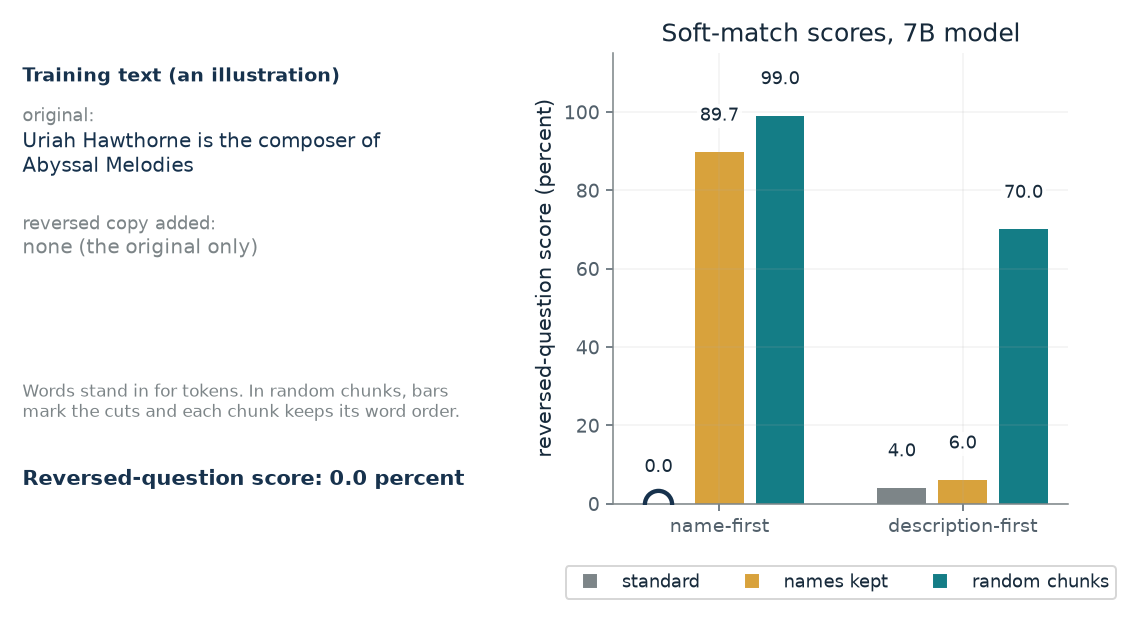

- **Reversed-question score:** 0.0 percent
- **Standard fine-tuning, same facts:** 0.0 percent
- **Gain over standard:** 0.0 points
- **Forward accuracy:** 78.3 to 80.3 percent

On name-first facts, reversed questions scored 0.0 percent with standard fine-tuning, against 0.0 with standard fine-tuning. These are soft-match scores from one preprint on invented facts, not like for like with the exact-match scores of the previous demonstration.

Reported scores (the chapter's Figure 8.5): name-first facts, standard fine-tuning: 0.0. Gain = 0.0 - 0.0 = 0.0 points. The number of facts and runs behind the table is not stated.

In [5]:
figure, values, explanation = reverse_training_picture(**{'kind': 'name-first', 'method': 'standard fine-tuning'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does adding reversed copies of the text buy?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Fact kind = description-first, Training = names kept in order: On description-first facts, keeping names in order moved the score only from 4.0 to 6.0 percent, while random chunks reached 70.0. Name-first facts jumped from 0.0 to 89.7 and 99.0.

**Takeaway:** Reversed copies repaired the symptom on name-first facts, but the gain depended on the kind of fact and the grain of reversal.

**Why it matters:** Giving a system the reverse direction in its training data is one way to supply direction. The cost is that every passage is used twice, and the repair is reported for a particular test, not for every kind of knowledge.

**In brains and behavior:** Nothing in this experiment concerns people.

**In machines:** A behavior measured on one 7B model in one preprint. The reversal sketched on the left shows the mechanical idea only.

**Where it applies:** A preprint, not peer reviewed in the chapter's account. The number of facts, runs and spread behind the table is not stated. Soft match is more generous than exact match, so these scores are not like for like with the previous demonstration. Forward accuracy of 78.3 to 80.3 percent is quoted for the name-first rows only in the chapter's source note.

**Check your understanding:** How many points does random-chunk training gain over standard fine-tuning on description-first facts?

<details><summary>Show the answer</summary>

70.0 - 4.0 = 66.0 points, against 6.0 - 4.0 = 2.0 points for names kept in order.

</details>

*Source: Chapter 8, Training on reversed copies of the facts. Reported results quoted in the chapter from Golovneva and colleagues (2024 preprint, Table 6): a 7-billion-parameter Llama-2 model on invented facts, reversed questions, soft match. The sentence shown on the left is the chapter's own invented fact; the reversal shown is this companion's sketch of the operation as the chapter describes it, with words standing in for tokens.*

## C08-D05: Why can a model learn A to B and still miss B to A?

In a tiny lookup with separate input and output vectors, what happens to the reversed question as the forward fact is learned, and what does a reversed copy change?

Each entity has two vectors, one used as the question and one as an answer. Learning that b answers a moves the question vector of a and the answer vector of b. The reversed question starts from the question vector of b, which was not moved, so its answer stays near chance. A reversed copy trains those parameters directly.

$$
p(y\mid x)=\frac{e^{\mathbf u_x\cdot\mathbf v_y}}{\sum_j e^{\mathbf u_x\cdot\mathbf v_j}}
$$

**Symbols:** u_x: input vector of entity x, used when x is the question; v_y: output vector of entity y, used when y is a candidate answer; p(y | x): the toy's chance of answering y when asked about x

**Predict before looking:** After 50 steps on forward facts only, will the reversed question be answered better than chance? Then add reversed copies and predict again.

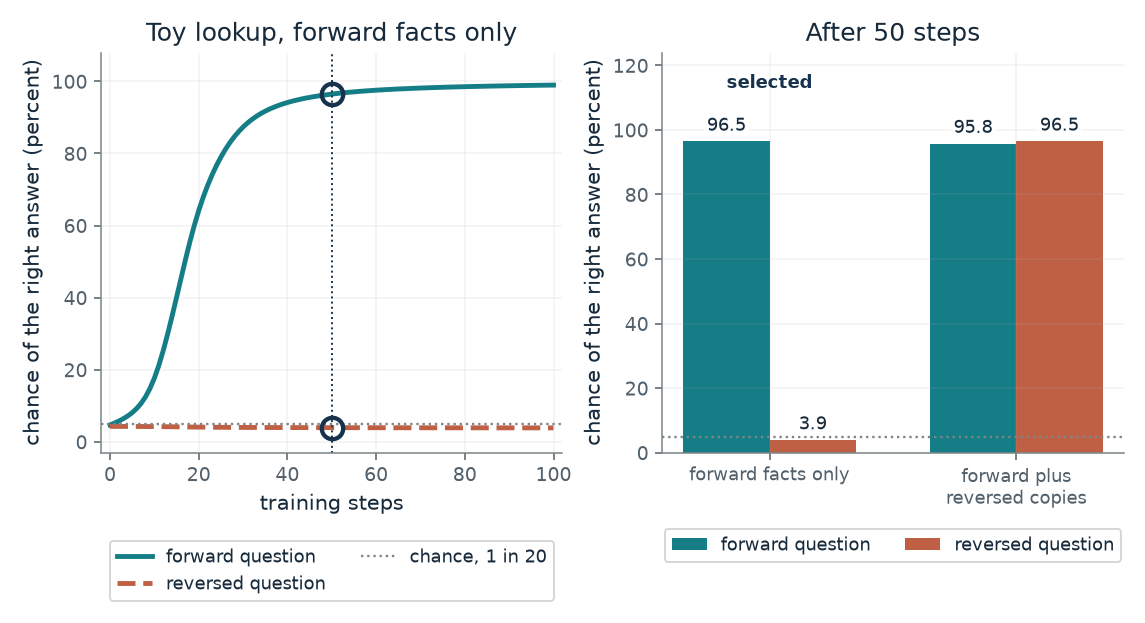

- **Forward question:** 96.5 percent
- **Reversed question:** 3.9 percent
- **Chance level:** 5.0 percent
- **Facts trained:** 5, each as a to b

After 50 steps of forward facts only among 20 entities, the toy answers the forward question 96.5 percent of the time and the reversed one 3.9 percent, against 5.0 by chance. This is a constructed toy with a seeded start, not a language model and not a theorem.

Each entity has an input vector and an output vector (8 numbers each, seed 2026). A question about x gets chance exp(u_x . v_y) / sum over j of exp(u_x . v_j) for answer y. Training moves only the vectors involved, 5 facts, step size 0.1, 50 steps.

In [6]:
figure, values, explanation = toy_reversal_picture(**{'training': 'forward facts only', 'entities': 20, 'steps': 50})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why can a model learn A to B and still miss B to A?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Training text = forward facts only, Entities in the toy = 20, Training steps = 50: After 50 steps the forward question is answered about 96 percent of the time and the reversed one about 3.9 percent, a little below the 5 percent chance level. Adding reversed copies lifts the reversed question to about 96 percent too.

**Takeaway:** In this toy the reverse direction is a separate lookup that forward training never touches, and training on the reversed copy supplies it.

**Why it matters:** It gives a concrete way to see why a system can hold a fact in one direction only: the parameters that serve the reverse question are different parameters. A repair has to reach them.

**In machines:** A seeded toy of the mechanism the chapter's references discuss. No claim about how real models store facts follows from it.

**Where it applies:** A simulation is a computation, not a measurement. The toy has no language, no paraphrases and no pretraining. A question about b uses the input vector of b, which the forward facts never moved, so the reversed question can only change through small side effects; the chapter says nothing about how large models are organized.

**Check your understanding:** Why is the reversed answer not exactly at chance after training on forward facts only?

<details><summary>Show the answer</summary>

Training also pushes the answer vectors of other entities away from the trained question vectors. That shifts every answer slightly, so the reversed chance drifts a little below 5 percent instead of staying exactly there.

</details>

*Source: Chapter 8, GPT-3 learns facts in one order only. Constructed toy, in the spirit of the chapter's mention of a 2024 proof about a simple model where the A to B link grows while the B to A link stays small. It is this companion's own simulation, seed 2026, step size 0.1, 8 numbers per vector; it is not the proof, not their model, and not a language model.*

## C08-D06: How does a step on a line read a relation, and how does negating it read it backward?

If next town east is a step of one stride, what gap does the fact score, what happens when head and tail swap, and what does negating the step do?

The step takes the head point to a landing point. The fact fits when the landing point is the tail. If you swap head and tail but keep the step, the landing point is a stride past the old head, so the miss is twice the step. Negating the step on the swapped pair always reproduces the original gap, since |t - r - h| = |h + r - t|.

$$
f(h,r,t)=\lVert \mathbf h+\mathbf r-\mathbf t\rVert
$$

**Symbols:** h, t: the head and tail towns as points on the road (Ash at 0, Birch at 1); r: the relation step, here one stride east, +1; f: the gap between where the head plus the step lands and the tail; 0 is a perfect fit

**Predict before looking:** With Birch as head and Ash as tail, what is the gap for the eastward step, and what is it after you negate the step?

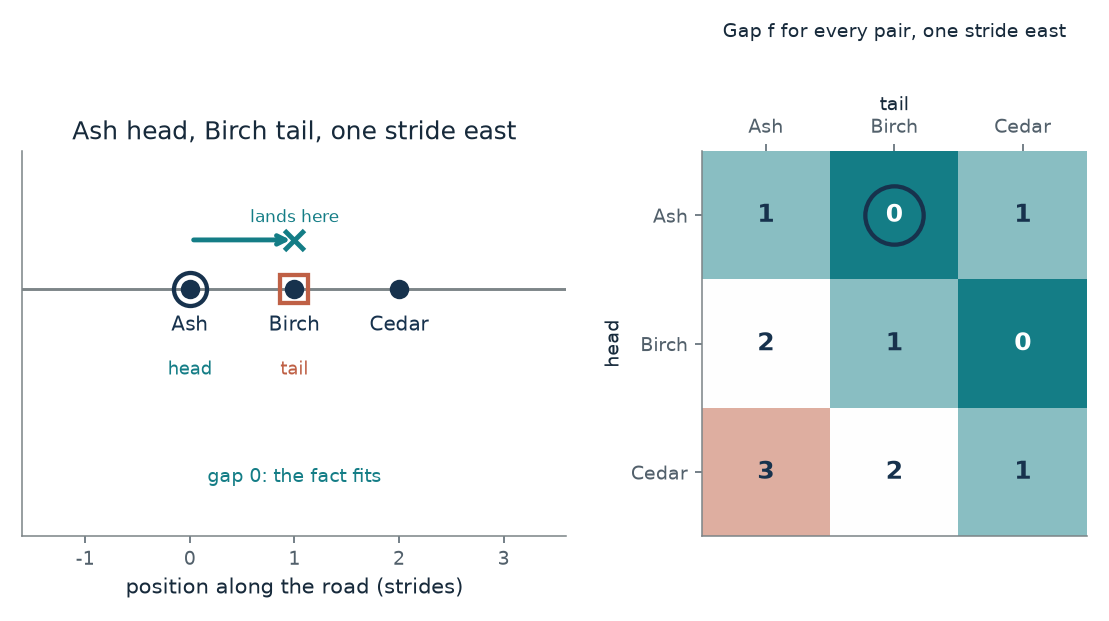

- **Gap f (strides):** 0
- **Step lands at:** Birch
- **Fits exactly:** yes
- **Swap head and tail, same step:** 2 strides

From Ash at 0, a step of +1 lands at 1, and the tail Birch is at 1, so the gap is 0 strides. Swapping the roles with the same step gives a gap of 2 strides; negating the step on the swapped pair always gives back 0.

f = |h + r - t| = |0 + (1) - 1| = 0. Swapped, same step: |1 + (1) - 0| = 2. Swapped with the negated step: |1 + (-1) - 0| = 0.

In [7]:
figure, values, explanation = translation_picture(**{'head': 'Ash', 'tail': 'Birch', 'step': 'one stride east'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a step on a line read a relation, and how does negating it read it backward?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Head town = Birch, Tail town = Ash, Relation step = one stride east: With Birch as head and Ash as tail the eastward step lands at Cedar, 2 strides past the tail, so the gap is 2. Switch the step to one stride west and the gap closes to 0.

**Takeaway:** Swapping head and tail with the same step misses by twice the step; negating the step reads the relation backward and the miss closes.

**Why it matters:** A translation score builds direction into the geometry: the fact fits one way, and the reverse costs a sign. The cost is that a relation true in both directions cannot keep a nonzero step.

**In machines:** TransE is a published model for scoring facts in a knowledge base; the line of towns is an illustration. The reversal by negating the step follows from the algebra, not from the paper.

**Where it applies:** Each relation is one fixed step, and an entity has the same point as head or as tail. A relation that holds both ways, such as sibling of, breaks the trick: an exact fit both ways forces the step to zero and puts the two entities at the same point. Nothing here shows that language models represent relations this way.

**Check your understanding:** With Ash as head, Cedar as tail and the eastward step, what is the gap?

<details><summary>Show the answer</summary>

Ash at 0 plus 1 lands at 1, the tail Cedar is at 2, so the gap is 1 stride.

</details>

*Source: Chapter 8, A relation became a step, and reversing the step read it backward. Book equation (the TransE score of Bordes and colleagues, 2013) and the chapter's town example: Ash at 0, Birch at 1, an eastward step of 1. Cedar at 2 is added by this companion as a third constructed town. The paper does not discuss reading a relation backward; the negated step is the chapter's own short algebra.*

## C08-D07: What does a hits-at-k score count?

If a model ranks every town as a candidate tail, how often does the true tail land in the top k, and how fast does that fall as the learned positions blur?

For each head, every other town is ranked by its gap to where the head plus the step lands. The true tail is rank 1 when positions are exact. As each position is blurred, other towns can land nearer, and the true tail slides down the ranking. Hits at k is the share of tests that stay in the top k.

$$
\text{hits at }k=\frac{\text{tests where the true tail ranks in the top }k}{\text{tests}}
$$

**Symbols:** rank: 1 plus the number of other candidates with a smaller gap f than the true tail; k: the cutoff: the true tail counts if its rank is at most k; noise sd: spread of the error added to each learned position, in strides

**Predict before looking:** With 29 candidates, what hits-at-10 would pure guessing give? Then predict how large the error in each position must be before the true tail falls outside the top 3 in half the tests.

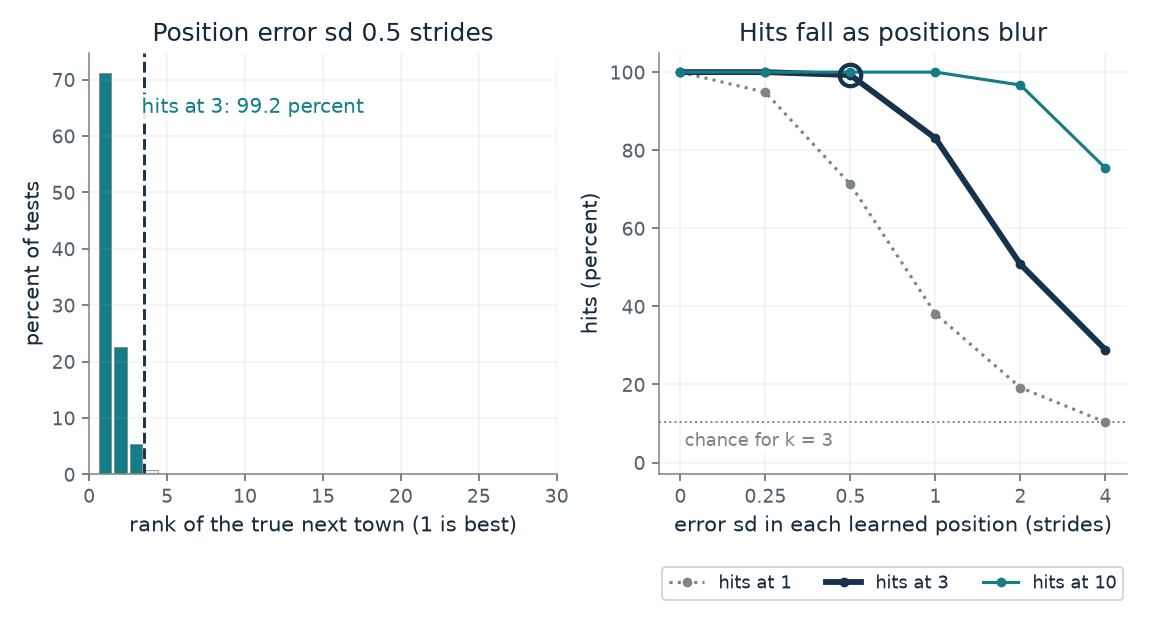

- **Hits at 3:** 99.2 percent
- **Chance level:** 10.3 percent
- **Median rank of the true town:** 1
- **Tests:** 5800 (200 blurs x 29 towns)

With each learned position blurred by sd 0.5 strides, the true next town ranks in the top 3 in 99.2 percent of tests, against 10.3 by chance among 29 candidates. This is a constructed road of 30 towns, not a benchmark, and its numbers do not compare with the paper's.

Rank of the true tail = 1 + the number of other towns whose gap |h + 1 - t| is smaller than the true gap. Hits at 3 = tests with rank <= 3 divided by 5800. Positions are the integers 0 to 29 plus normal error with sd 0.5, seed 2026.

In [8]:
figure, values, explanation = hits_picture(**{'noise': 0.5, 'k': 3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a hits-at-k score count?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Error sd in each learned position (strides) = 1, Cutoff k = 3: At an error sd of 1 stride, equal to the spacing between towns, the true tail ranks in the top 3 in 83.1 percent of tests but is the single best guess in only 38.1 percent. Chance for k = 3 is 10.3 percent, and at sd 0 every test is a hit at 1.

**Takeaway:** Hits at k measures whether the true answer is near the top of a ranking, so it is read against the chance level k over the number of candidates.

**Why it matters:** A hits number means little until you know the candidate list and the chance level. It also says nothing about reading a relation backward, which the benchmark did not test.

**In machines:** The ranking by the gap f is the specification from the chapter; the benchmark numbers are 2013 results against 2013 competitors.

**Where it applies:** A simulation is not a measurement. The road is a single relation with exact steps plus normal error, so it is far easier than a knowledge base with many relations, and its percentages do not compare with the paper's. With one true tail per head, the filtered and unfiltered rankings agree here.

**Check your understanding:** With 29 candidates, what share of tests would random ranking put in the top 10?

<details><summary>Show the answer</summary>

10 / 29, about 34.5 percent. A hits-at-10 score is only informative once it is read against that level.

</details>

*Source: Chapter 8, A relation became a step, and reversing the step read it backward. The metric is the chapter's: hits at 10 in the filtered evaluation, 89.2 percent on WordNet and 47.1 percent on FB15k in 2013 benchmarks. Those figures are not recomputed. The road of 30 towns and its blurred positions are this companion's constructed simulation, seed 2026, 200 blurs.*

## Bring it to your own question

Ask how each fact is stored: with head, relation and tail marked, or as a bare association. If the facts live in a graph, flip the grid and check whether the reversed relation is the one intended (has mother is not child of). If the facts live in a trained model, test both directions on held-out wordings, and compare reported scores only when the scoring rule is the same. Say which of the three the system relies on: direction kept by design, recovered by training on reversed text, or built into the geometry.

Use the `mmi-ch08-knowing-things-relate` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.